In [1]:
%%capture
!pip install keras-tuner --upgrade

In [1]:
# Importing Libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.offsetbox import AnchoredText
import matplotlib.colors as colors
from mpl_toolkits import mplot3d
from math import sqrt
import warnings
import time

from sklearn.metrics import mean_squared_error,r2_score,mean_absolute_error
from sklearn.model_selection import train_test_split,KFold,cross_val_score,GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder,LabelEncoder, MinMaxScaler


from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor,AdaBoostRegressor,ExtraTreesRegressor,BaggingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.cross_decomposition import PLSRegression
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import GridSearchCV


import keras_tuner as kt
from tensorflow import keras

import tensorflow as tf
import keras
from keras import layers
from keras.models import Sequential
from keras.layers import Dense
from keras.models import load_model
from tensorflow.keras.callbacks import EarlyStopping

import pickle
import os
import random


import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (6,6)
plt.rcParams['savefig.dpi'] = 300
plt.rcParams["savefig.format"] = 'tiff'
warnings.filterwarnings("ignore")

In [2]:
seed = 76
os.environ['PYTHONHASHSEED'] = str(seed)
random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)

In [3]:
sns.set(style='whitegrid')
sns.set_context("paper", font_scale=1.7)

In [4]:
# To print losses
def plots():
    f, ax = plt.subplots(1,1)
    actual_val=np.array(scaler.inverse_transform(valY).reshape(-1,1))
    predicted_val=np.array(scaler.inverse_transform(model.predict(valX).reshape(-1,1)))
    actual_test=np.array(scaler.inverse_transform(testY).reshape(-1,1))
    predicted_test=np.array(scaler.inverse_transform(model.predict(testX).reshape(-1,1)))

    #actual=testY
    #predicted= model.predict(testX)

    actual=np.array(scaler.inverse_transform(np.array(trainY).reshape(-1,1)))
    predicted=np.array(scaler.inverse_transform(model.predict(np.array(trainX)).reshape(-1,1)))

    plt.rcParams["figure.figsize"] = (6,6)
    plt.rcParams['savefig.dpi'] = 300
    plt.rcParams["savefig.format"] = 'tiff'

    sns.set(style='whitegrid')
    sns.set_context("paper", font_scale=1.7)

    plt.scatter(actual_test,predicted_test, color='purple', label='Test', linewidths=1, edgecolors='black', s=75)
    sns.regplot(x=actual,y=predicted, color='orangered', label='Train', scatter_kws={'s':40, 'alpha':0.5, 'edgecolor':'black'})
    print("R square (R^2) for train:                 %f" % r2_score(actual,predicted))
    print("R square (R^2) for val:                 %f" % r2_score(actual_val,predicted_val))
    print("Mean absolute error (MAE)- Test:      %f" % mean_absolute_error(actual_test,predicted_test))
    print("Mean squared error (MSE)- Test:       %f" % mean_squared_error(actual_test,predicted_test))
    print("Root mean squared error (RMSE) - Test: %f" % sqrt(mean_squared_error(actual_test,predicted_test)))
    print("R square (R^2) - Test:                 %f" % r2_score(actual_test,predicted_test))


    plt.xlabel('Actual')
    plt.ylabel('Predicted')
    #plt.suptitle("Actual Vs Predicted")
    anchored_text = AnchoredText("R\u00b2 Score_train  "+str(round(r2_score(actual,predicted),3))+'\n'"R\u00b2 Score_test  "+str(round(r2_score(actual_test,predicted_test),3)), loc=2,prop=dict(size=10))
    # anchored_text = AnchoredText("R\u00b2 Score =  "+str(round(r2_score(actual_test,predicted_test),3)), loc=2,prop=dict(size=15))
    ax.add_artist(anchored_text)

    plt.legend(loc = 9, prop={'size': 10}) #labels=["Test","Train"],
    plt.tight_layout()
    plt.savefig(str(model)[1:6], bbox_inches='tight')

In [5]:
df = pd.read_excel('data.xlsx')

In [6]:
df.head(2)

,ID,TYPE,NICS(0),Can SMILES,ABC,nAcid,nBase,SpMAD_A,nAromAtom,nBridgehead,...,bpol,n7Ring,nHRing,n6HRing,n5ARing,nAHRing,SLogP,JGI5,JGI6,TSRW10
0,A1,Methylbenzene,-8.03,c1ccccc1,4.242641,0,0,1.333333,6,0,...,6.019242,0,0,0,0,0,1.68660,0.0,0.0,30.941317
1,A2,Methylbenzene,-8.01,Cc1ccccc1,5.059137,0,0,1.245795,6,0,...,8.025656,0,0,0,0,0,1.99502,0.0,0.0,33.544698


In [7]:
df.shape

(503, 193)

In [8]:
with open('train_ids.pkl', 'rb') as f:
    train_ids = pickle.load(f)


with open('val_ids.pkl', 'rb') as f:
    val_ids = pickle.load(f)

with open('test_ids.pkl', 'rb') as f:
    test_ids = pickle.load(f)

Train = df[df['ID'].isin(train_ids)].set_index('ID').loc[train_ids].reset_index()
Val = df[df['ID'].isin(val_ids)].set_index('ID').loc[val_ids].reset_index()
Test = df[df['ID'].isin(test_ids)]

In [9]:
Train.head(2)

,ID,TYPE,NICS(0),Can SMILES,ABC,nAcid,nBase,SpMAD_A,nAromAtom,nBridgehead,...,bpol,n7Ring,nHRing,n6HRing,n5ARing,nAHRing,SLogP,JGI5,JGI6,TSRW10
0,A252,Substituted Hetero Six-Membered Ring,-8.16,Nc1ccc([NH3+])cc1,5.875634,0,1,1.240597,6,0,...,7.318863,0,0,0,0,0,0.1422,0.0,0.0,35.730685
1,A300,Monoprotonated Borapyridine,-5.06,b1bc[nH+]cb1,4.242641,0,1,1.333333,6,0,...,6.299621,0,1,1,0,0,-1.4850,0.0,0.0,30.941317


In [10]:
Val.head(2)

,ID,TYPE,NICS(0),Can SMILES,ABC,nAcid,nBase,SpMAD_A,nAromAtom,nBridgehead,...,bpol,n7Ring,nHRing,n6HRing,n5ARing,nAHRing,SLogP,JGI5,JGI6,TSRW10
0,A372,Mono-Substituted Benzene,-6.02,[C-]#Cc1ccccc1,5.656854,1,0,1.303037,6,0,...,5.016035,0,0,0,0,0,1.62449,0.0625,0.0,35.247635
1,A426,Meta-Substituted Pyridine,-5.46,[Li][c]1cccnc1,5.059137,0,0,1.245795,6,0,...,27.812828,0,1,1,0,0,-0.12460,0.0000,0.0,33.544698


In [11]:
Val.shape

(50, 193)

In [12]:
# Combine Train and test for feature engineering
DF_raw = pd.concat([Train,Val, Test],ignore_index=True)
DF_data = DF_raw.copy()

In [13]:
DF_data = DF_data[['NICS(0)','nB', 'Xch-5d', 'n6HRing', 'n7Ring', 'ATSC3s', 'ETA_beta_ns_d',
                   'ATSC4v', 'BCUTZ-1l', 'nHRing', 'VSA_EState6', 'bpol', 'TSRW10',
                   'NaaCH', 'AMID', 'IC0']]


In [14]:
DF_data.head(2)

,NICS(0),nB,Xch-5d,n6HRing,n7Ring,ATSC3s,ETA_beta_ns_d,ATSC4v,BCUTZ-1l,nHRing,VSA_EState6,bpol,TSRW10,NaaCH,AMID,IC0
0,-8.16,0,0.0,0,0,-3.270281,1.0,-301.460858,5.697914,0,7.439815,7.318863,35.730685,4,1.941604,1.379280
1,-5.06,3,0.0,1,0,-0.111111,0.0,-278.489944,4.778874,1,0.000000,6.299621,30.941317,2,1.968750,1.891061


In [15]:
# Scaling the whole DataFrame

scaler = StandardScaler()
scaled_DF = pd.DataFrame(scaler.fit_transform(DF_data.iloc[:,1:]))
scaled_DF.columns = DF_data.iloc[:,1:].columns

scaled_DF['NICS(0)'] = scaler.fit_transform(np.array(DF_data['NICS(0)']).reshape(-1,1))
scaled_DF

display(scaled_DF)

,nB,Xch-5d,n6HRing,n7Ring,ATSC3s,ETA_beta_ns_d,ATSC4v,BCUTZ-1l,nHRing,VSA_EState6,bpol,TSRW10,NaaCH,AMID,IC0,NICS(0)
0,-0.263603,-0.520197,-0.885325,-0.089532,-0.165126,1.112714,-0.751372,-0.006193,-1.387307,1.035969,-0.357699,-0.233404,0.585890,-0.425775,-0.598434,0.206000
1,3.879907,-0.520197,1.111619,-0.089532,0.200020,-0.538304,-0.669026,-1.064936,0.708235,-0.990015,-0.505356,-1.152398,-0.750631,0.996955,1.166971,0.932012
2,-0.263603,-0.520197,-0.885325,-0.089532,-0.737485,1.112714,-0.279720,-0.005422,-1.387307,0.752306,-0.483216,-0.233404,0.585890,-0.425775,0.034646,-0.044591
3,-0.263603,1.986382,-0.885325,-0.089532,0.205348,-0.538304,0.329312,0.336056,0.708235,-0.990015,-0.664193,0.778604,-1.418891,-0.640846,0.826916,-1.077401
4,-0.263603,-0.520197,1.111619,-0.089532,0.068175,0.287205,0.453647,0.033205,0.708235,-0.009802,-0.463399,-0.652856,0.585890,0.215118,-0.318317,0.498747
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
498,-0.263603,-0.520197,1.111619,-0.089532,0.132696,-0.538304,-1.699903,0.019841,0.708235,0.114379,0.055178,-0.326093,0.585890,0.621345,-1.033016,0.468301
499,-0.263603,-0.520197,1.111619,-0.089532,0.152930,-0.538304,-0.194818,-3.118874,0.708235,0.114379,2.674004,-0.652856,0.585890,0.215118,0.335500,0.655659
500,1.117567,-0.520197,1.111619,-0.089532,0.031494,-0.538304,-0.521196,-0.824547,0.708235,0.114379,0.273001,-0.652856,0.585890,0.215118,0.074698,0.405068
501,-0.263603,-0.520197,1.111619,-0.089532,-0.231991,0.287205,-0.031834,0.034007,0.708235,-0.127680,-0.463399,-0.652856,0.585890,0.215118,0.212380,0.376964


In [16]:
DF_target = scaled_DF[['NICS(0)']]
scaled_DF.drop('NICS(0)',axis=1,inplace=True)

In [17]:
Train.shape

(402, 193)

In [18]:
trainX = scaled_DF.iloc[:402, :]
valX = scaled_DF.iloc[402:452, :]
testX = scaled_DF.iloc[452:,:]

trainY = DF_target.iloc[:402, :]
valY = DF_target.iloc[402:452, :]
testY = DF_target.iloc[452:, :]

In [19]:
totalX = pd.concat([trainX,valX, testX], axis=0)
totalY = pd.concat([trainY, valY, testY], axis=0)

In [ ]:
# Define the learning rate scheduler
def scheduler(epoch, lr):
    if epoch < 160:
        return lr
    else:
        return lr * np.exp(-0.1)

callback = keras.callbacks.LearningRateScheduler(scheduler)


# Define the model builder for Keras Tuner
def model_builder(hp):
    init = keras.initializers.RandomNormal()
    model = Sequential()
    batch_size = hp.Choice('batch_size', values=[16, 32, 64])

    # Input layer
    model.add(layers.Dense(
        units=hp.Int('units_input', min_value=16, max_value=128, step=16),
        activation='relu',
        kernel_initializer=init,
        input_dim=scaled_DF.shape[1]
    ))
    model.add(layers.Dropout(hp.Float('dropout_input', min_value=0.1, max_value=0.5, step=0.1)))

    # Hidden layers
    for i in range(hp.Int('num_hidden_layers', 1, 2)):
        model.add(layers.Dense(
            units=hp.Int(f'units_hidden_{i}', min_value=64, max_value=256, step=64),
            activation='relu',
            kernel_initializer=init
        ))
        model.add(layers.Dropout(hp.Float(f'dropout_hidden_{i}', min_value=0.1, max_value=0.5, step=0.1)))

    # Output layer
    model.add(layers.Dense(1, kernel_initializer=init, activation='linear'))

    # Optimizer and learning rate
    learning_rate = hp.Choice('learning_rate', values=[1e-2, 1e-3, 1e-4])
    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)

    model.compile(optimizer=optimizer, loss='mse')
    return model


class MyTuner(kt.Hyperband):
    def run_trial(self, trial, *args, **kwargs):
        hp = trial.hyperparameters

        kwargs['batch_size'] = hp.get('batch_size')

        return super(MyTuner, self).run_trial(
            trial, *args, **kwargs
        )


tuner = MyTuner(
    model_builder,
    objective='val_loss',
    max_epochs=200,
    factor=3,
    directory='my_dir',
    project_name='tuning_neural_network'
)


# Search for the best hyperparameters
tuner.search(
    trainX, trainY,
    epochs=200,
    validation_data=(valX, valY),
    callbacks=[callback]
)


# Get the best hyperparameters
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]


# Build and train the best model
best_model = tuner.hypermodel.build(best_hps)

history = best_model.fit(
    trainX, trainY,
    epochs=200,
    batch_size=best_hps.get('batch_size'),
    validation_data=(valX, valY),
    callbacks=[callback],
    verbose=1
)


# Print the optimal hyperparameters
print("Optimal Hyperparameters:")

for param, value in best_hps.values.items():
    print(f"{param}: {value}")

Trial 254 Complete [00h 00m 41s]
val_loss: 0.12514735758304596

Best val_loss So Far: 0.07115376740694046
Total elapsed time: 00h 34m 38s
Epoch 1/200
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 1.0850 - val_loss: 0.3560 - learning_rate: 0.0010
Epoch 2/200
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.9535 - val_loss: 0.2479 - learning_rate: 0.0010
Epoch 3/200
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.7405 - val_loss: 0.1630 - learning_rate: 0.0010
Epoch 4/200
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.5736 - val_loss: 0.2038 - learning_rate: 0.0010
Epoch 5/200
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.5038 - val_loss: 0.1929 - learning_rate: 0.0010
Epoch 6/200
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.5011 - val_loss: 0.1719 - learning_rate: 0.0010
Epoch 7/200
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.4525 - val_loss: 0.1653 - learning_rate: 0.0010
Epoch 8/200
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.4384 - val_loss: 0.1466 - learning_rate: 0.001

In [20]:
# Learning Rate Scheduler
def scheduler(epoch, lr):
  if epoch < 160:
    return lr
  else:
    return lr * np.exp(-0.1)

callback = keras.callbacks.LearningRateScheduler(scheduler)

# Neural Network
def Neural_network():
    # Initialize weights with a random normal initializer
    init = keras.initializers.RandomNormal()
    model = Sequential()

    # Input Layer
    model.add(layers.Dense(
        64,
        activation='relu',
        kernel_initializer=init,
        input_dim=scaled_DF.shape[1]
    ))
    model.add(layers.Dropout(0.1))  # 10% dropout as per optimal parameters

    # first Hidden Layer
    model.add(layers.Dense(
        192,
        activation='relu',
        kernel_initializer=init
    ))
    model.add(layers.Dropout(0.2))  # 20% dropout as per optimal parameters

    # second hidden
    model.add(layers.Dense(
            256,
            activation='relu',
            kernel_initializer=init
        ))
    model.add(layers.Dropout(0.4))  # 40% dropout as per optimal parameters

    # Output Layer
    model.add(layers.Dense(
        1,
        kernel_initializer=init,
        activation='linear'  # Linear activation for regression
    ))

    # Optimizer
    optimize = tf.keras.optimizers.Adam(learning_rate=0.001)  # Optimal learning rate

    # Compile the model
    model.compile(
        optimizer=optimize,
        loss='mse'  # Mean Squared Error for regression tasks
    )
    return model

# Training Function
def training_model(X_train, Y_train, model, X_val, Y_val):
    # Include callbacks: LearningRateScheduler and optional EarlyStopping
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=45,
        min_delta=0.001,
        restore_best_weights=True
    )

    history = model.fit(
        trainX, trainY,
        epochs=200,
        batch_size=64,
        validation_data=(valX, valY),  # Add validation data
        verbose=1,  # Set verbose to 1 for training logs
        callbacks=[callback, early_stopping]  # Add callbacks
    )
    return history


In [21]:
tf.keras.backend.clear_session()
model = Neural_network()
# Define Callbacks

history = training_model(trainX, trainY, model, valX, valY)

Epoch 1/200
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 1.0834 - val_loss: 0.3484 - learning_rate: 0.0010
Epoch 2/200
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.9578 - val_loss: 0.2449 - learning_rate: 0.0010
Epoch 3/200
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.7637 - val_loss: 0.1676 - learning_rate: 0.0010
Epoch 4/200
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.6233 - val_loss: 0.1783 - learning_rate: 0.0010
Epoch 5/200
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.5332 - val_loss: 0.1643 - learning_rate: 0.0010
Epoch 6/200
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.4700 - val_loss: 0.1619 - learning_rate: 0.0010
Epoch 7/200
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.4693 - val_loss: 0.1693 - learning_rate: 0.0010
Epoch 8/200
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.4886 - val_loss: 0.1516 - learning_rate: 0.0010
Epoch 9/200
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.4295 - val_loss: 0.1492 - learning_rate: 0.0010
Epoch 10/200
7/7 ━━━━━━━━━━━

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
R square (R^2) for train:                 0.945166
R square (R^2) for val:                 0.823447
Mean absolute error (MAE)- Test:      0.709897
Mean squared error (MSE)- Test:       0.887304
Root mean squared error (RMSE) - Test: 0.941968
R square (R^2) - Test:                 0.929994


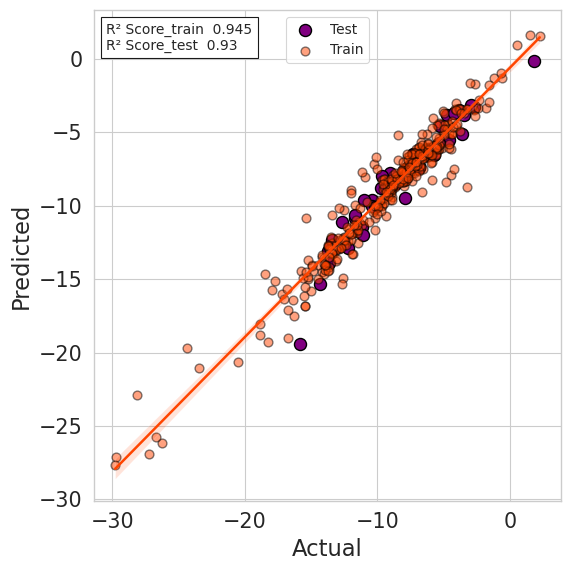

In [ ]:
plots()

In [ ]:
model = load_model('/content/nn_tuned.keras')

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
R square (R^2) for train:                 0.945166
R square (R^2) for val:                 0.823447
Mean absolute error (MAE)- Test:      0.709897
Mean squared error (MSE)- Test:       0.887304
Root mean squared error (RMSE) - Test: 0.941968
R square (R^2) - Test:                 0.929994


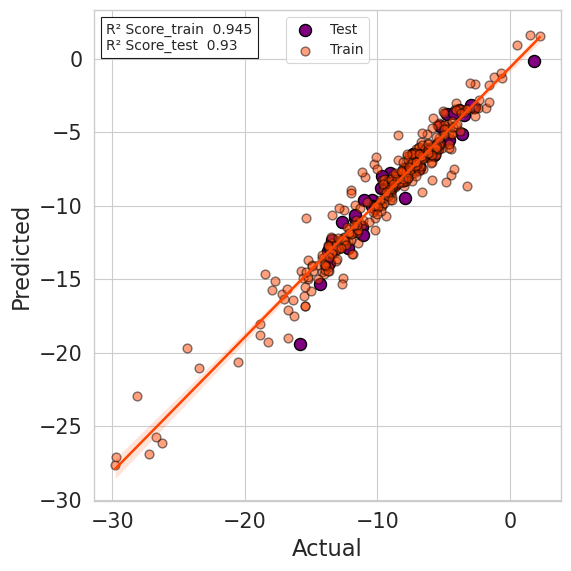

In [ ]:
plots()

In [23]:

def training_model(X_train,Y_train,model):
    history=model.fit(X_train,Y_train,epochs=200,batch_size=64,verbose=0)
    return history

In [24]:
# cross-validation on new tuned model

kfold = KFold(n_splits=5, shuffle=True, random_state=42)

scores = []
rmse = []
for train,valid in kfold.split(totalX,totalY):
  model = load_model('nn_tuned.keras')
  training_model(totalX.iloc[train],totalY.iloc[train],model)
  scores.append(r2_score(totalY.iloc[valid],model.predict(totalX.iloc[valid])))

  actual = totalY.iloc[valid]
  predicted = model.predict(totalX.iloc[valid])
  rmse.append(sqrt(mean_squared_error(scaler.inverse_transform(actual),scaler.inverse_transform(predicted))))

print("Average validation R2 score after crossvalidation : ", np.mean(scores))
print("Average validation rmse score after crossvalidation : ", np.mean(rmse))

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
Average validation R2 score after crossvalidation :  0.8991436123847961
Average validation rmse score after crossvalidation :  1.3114396159554886
